# 1. Problem

Recover the fraction-of-modes phonon density of states of experimentally measured vanadium. The observation contains single-phonon, multiphonon and multiple-scattering contributions; all depend on the same density. We preserve the complete 300-momentum-bin measurement and missing-cell mask. There is no independent measured DOS truth.

The selected method is the complete published numerical multiphonon correction with its original default20-update cap/tolerance1e-4, which stops after six updates. An original tighter100-update cap/tolerance1e-10 comparison stops after14. Both source runs and both fresh runs are explicitly distinguished. The evaluated target is the complete measured-Q marginal, not exact hidden density identity and not a claim of noise-limited two-dimensional fitting.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_observations,preprocess
from src.solvers import reconstruct,initial_density
from src.physics_model import *
from src import visualization as vis
vis.style()
raw=load_observations(ROOT/'data/raw_data.npz')
source=np.load(ROOT/'notebooks/reference_outputs/default_source.npz',allow_pickle=False)
tight_source=np.load(ROOT/'notebooks/reference_outputs/tight_source.npz',allow_pickle=False)
spec=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
start=time.perf_counter();fresh=run(ROOT);default_seconds=time.perf_counter()-start
start=time.perf_counter();tighter=reconstruct(*raw,max_iterations=100,tolerance=1e-10);tight_seconds=time.perf_counter()-start
measured,q=judge.observation(ROOT/'data/raw_data.npz')
print({'fresh_default_seconds':default_seconds,'fresh_default_updates':len(fresh['history']),'fresh_tighter_seconds':tight_seconds,'fresh_tighter_updates':len(tighter['history'])})

{'fresh_default_seconds': 0.014472200069576502, 'fresh_default_updates': 6, 'fresh_tighter_seconds': 0.01845940004568547, 'fresh_tighter_updates': 14}


# 2. Data

The raw intensity and variance retain float64 precision. NaNs denote acquisition gaps rather than measured zeros. The visible bool mask equals the finite intensity mask. Bilinear resampling to −15..79 meV restores the original per-row missing boundaries after interpolation. Positive energy transfer means neutron energy loss; momentum magnitude is in inverse ångströms. The source binding uses300K,50.94u,120meV incident energy, and multiple-scattering coefficient0.2. The original experimental metadata does not provide a verified acquisition date or run identifier, so none is invented.

findfont: Failed to find font weight semibold, now using 700.


{'original_shape': (300, 149), 'measured_cells': 31605, 'missing_cells': 13095, 'native_energy_range': [-59.4, 118.20000000000041]}


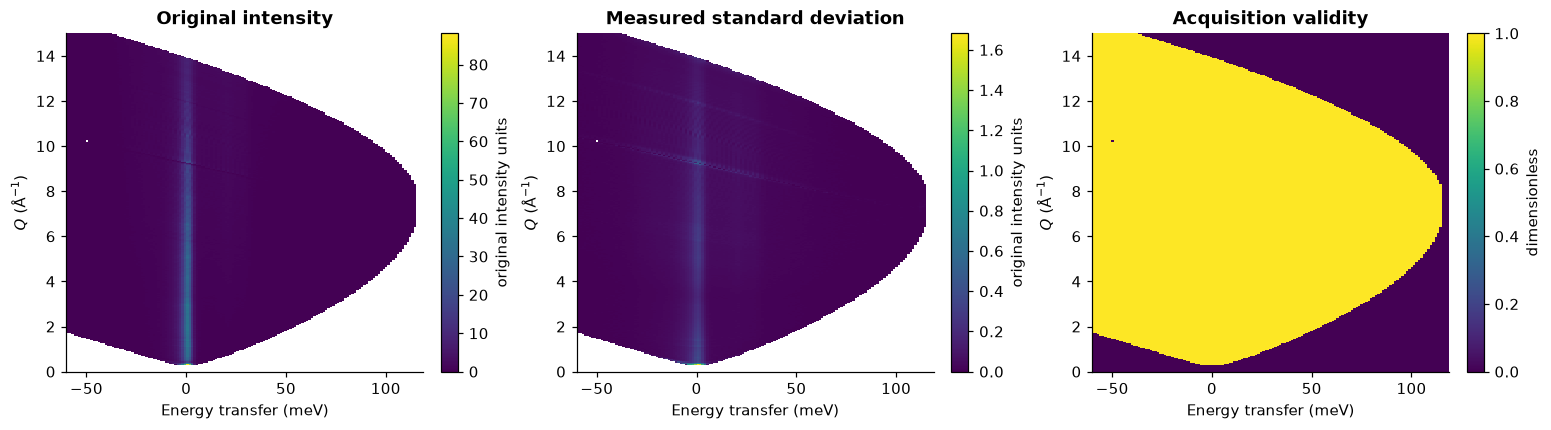

In [2]:
print({'original_shape':raw[0].shape,'measured_cells':int(np.isfinite(raw[0]).sum()),'missing_cells':int(np.isnan(raw[0]).sum()),'native_energy_range':raw[3][[0,-1]].tolist()})
display(vis.acquisition(*raw));plt.close()
assert np.isfinite(raw[1][np.isfinite(raw[0])]).all()

# 3. Physics

Let $g(E)$ be a normalized density in $\mathrm{meV}^{-1}$ and $\beta=1/(k_{\mathrm B}T)$ in $\mathrm{meV}^{-1}$. The thermal integral $\gamma$ has units $\mathrm{meV}^{-1}$, recoil exponent $d$ is dimensionless, and each spectral order $A_n$ is a density. The complete definitions, numerical constants, zero-energy extrapolation and convolution boundaries are specified in README.

$$A_1(E)=\frac{g(|E|)}{\gamma E[1-\exp(-\beta E)]},\qquad d(Q)=\gamma\frac{\hbar^2Q^2}{2M}.$$

$$F(Q,E)=e^{-d(Q)}\sum_{n=1}^{4}\frac{d(Q)^n}{n!}A_n(E)+U(Q,E).$$

Here $U$ is0.2 times the accessible-Q mean of orders2–4; the strict neutron triangle is applied before that mean. The density is zero above55meV and quadratic below7meV. The finite1meV discretization intentionally retains the source A1 mass bias. Higher orders are normalized after central linear convolution.

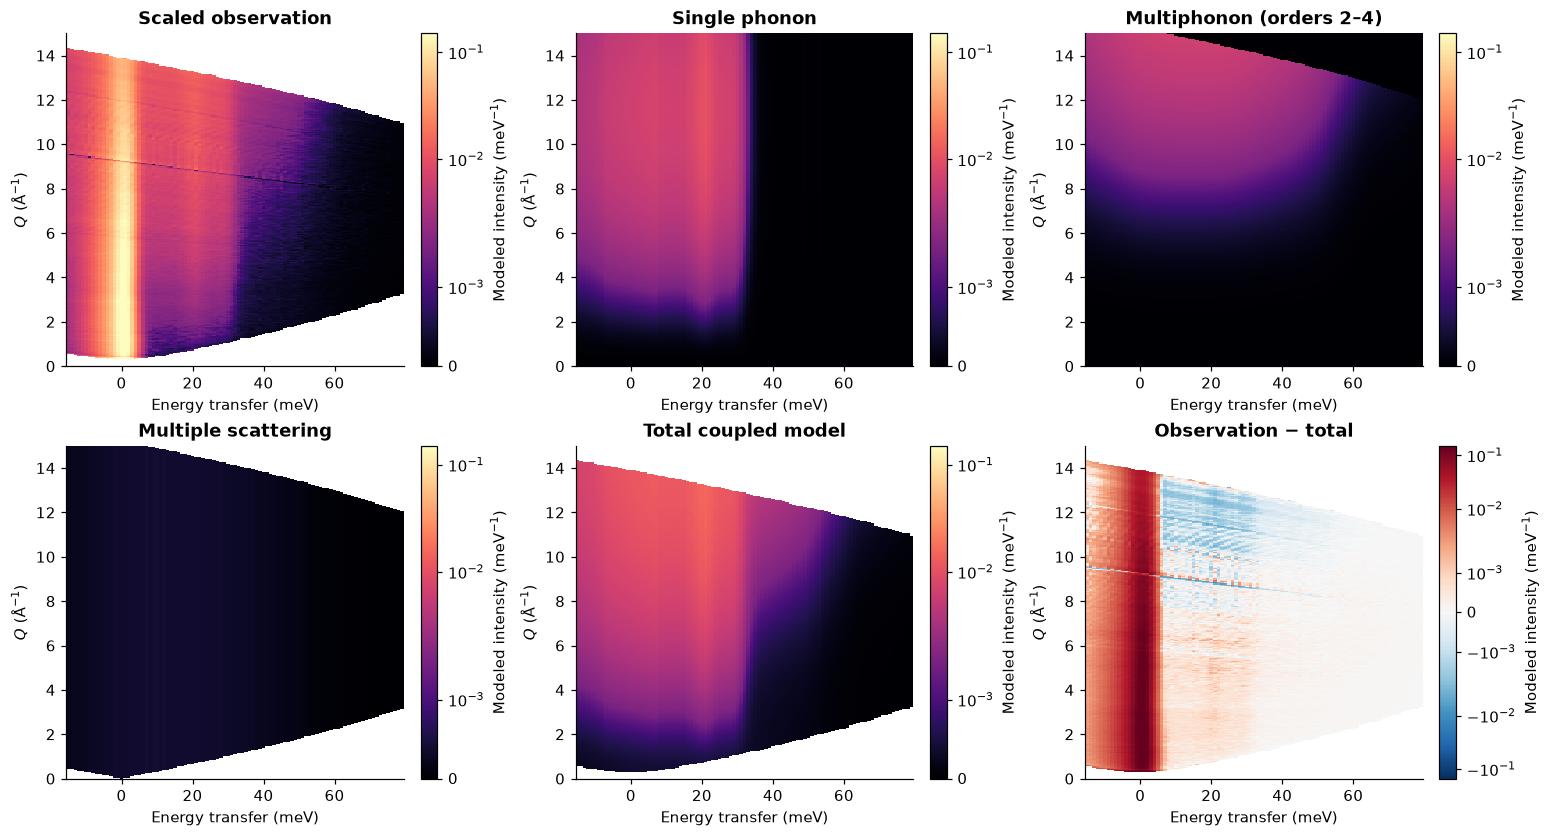

{'all_window_2d_relative_L2_including_elastic_region': np.float64(0.9456017174618225), 'inelastic_E_ge7_2d_relative_L2': np.float64(0.13854815218054808), 'inelastic_mean_variance_normalized_squared_residual': 148.88103985611303}


In [3]:
display(vis.decomposition(fresh,q));plt.close()
s=fresh['stages'][-1]
valid=np.isfinite(s['scaled_observation'])
two_d_all=np.linalg.norm((s['scaled_observation']-s['total'])[valid])/np.linalg.norm(s['scaled_observation'][valid])
inelastic=valid&(np.arange(-15,80)[None]>=7)
two_d=np.linalg.norm((s['scaled_observation']-s['total'])[inelastic])/np.linalg.norm(s['scaled_observation'][inelastic])
scale=np.nansum(s['total'][:,22:])/np.nansum(fresh['processed_intensity'][:,22:])
var=fresh['processed_variance']*scale**2
chi_valid=inelastic&(var>0)
chi=float(np.mean(((s['scaled_observation']-s['total'])[chi_valid]**2)/var[chi_valid]))
print({'all_window_2d_relative_L2_including_elastic_region':two_d_all,'inelastic_E_ge7_2d_relative_L2':two_d,'inelastic_mean_variance_normalized_squared_residual':chi})
assert .13<two_d<.15

# 4. Method

The reference alternates multiplicative single-phonon density updates with full multiphonon/multiple-scattering recalculation. The Debye–Waller exponent is recomputed from the current density. All measured Q bins contribute. Positivity, support, normalization and quadratic low-energy continuation constrain each update. Default convergence uses both relative and absolute1e-4 per-bin change; tighter comparison uses1e-10. Multiplicative zero trapping is a source limitation, so evaluation accepts any density meeting the declared public physical constraints and marginal residual.

No upstream histogram package or domain solver is imported by the cleaned reconstruction. Direct local formulas implement thermal populations, convolutions, recoil, kinematics, updates and uncertainty propagation.

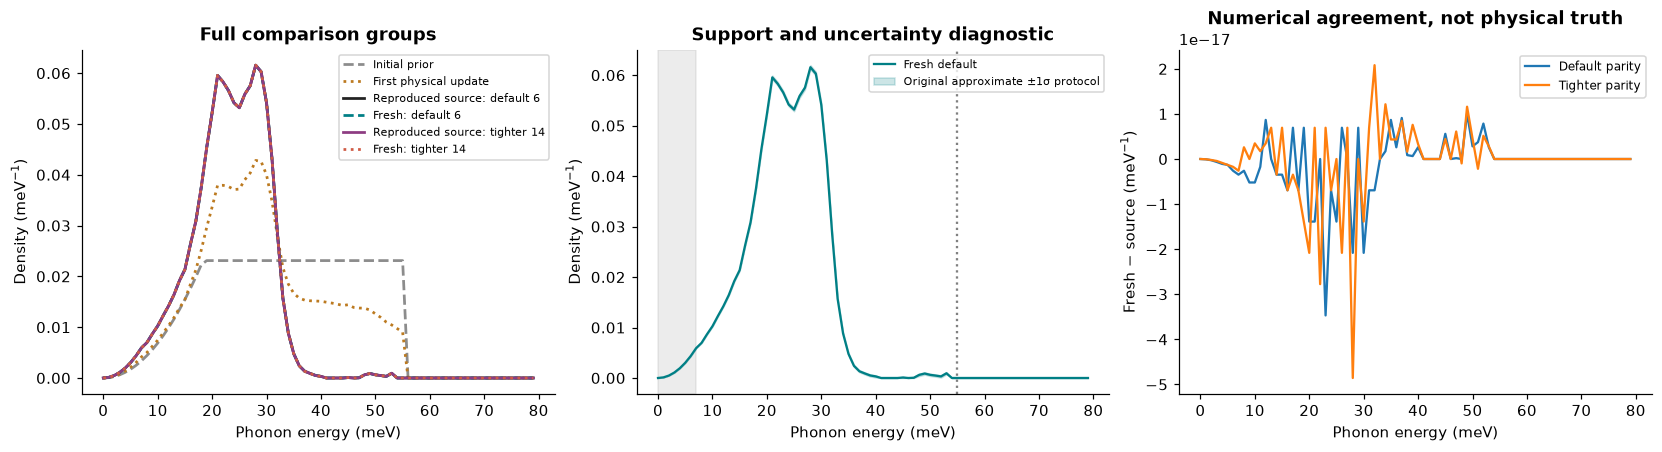

| Measurement | Q-marginal relative L2 | Normalization error |
| --- | --- | --- |
| Initial prior | 0.2572570008 | 0 |
| First fresh update | 0.1087826994 | 0 |
| Reproduced source default6 | 0.00722986988 | 0 |
| Fresh default6 | 0.00722986988 | 0 |
| Reproduced source tighter14 | 0.007244541488 | 0 |
| Fresh tighter14 | 0.007244541488 | 0 |

{'default_max_abs_source_difference': 3.469446951953614e-17, 'tighter_max_abs_source_difference': 4.85722573273506e-17}


In [4]:
display(vis.density_comparison(fresh,tighter,source,tight_source,initial_density()));plt.close()
groups=[('Initial prior',initial_density()),('First fresh update',fresh['history'][0]),('Reproduced source default6',source['final_g']),('Fresh default6',fresh['reconstruction']),('Reproduced source tighter14',tight_source['reconstruction']),('Fresh tighter14',tighter['reconstruction'])]
table=['| Measurement | Q-marginal relative L2 | Normalization error |','| --- | --- | --- |']
for name,g in groups:
    metric=judge.score(g,measured,q)
    table.append(f"| {name} | {metric['marginal_relative_l2']:.10g} | {metric['normalization_abs_error']:.3g} |")
display(Markdown('\n'.join(table)))
print({'default_max_abs_source_difference':float(np.max(abs(fresh['reconstruction']-source['final_g']))),'tighter_max_abs_source_difference':float(np.max(abs(tighter['reconstruction']-tight_source['reconstruction'])))})

# 5. Results

The public criterion compares the complete Q-integrated spectrum over7..79meV after a single physically defined inelastic-area normalization. It does not rescale the submitted density. The inelastic two-dimensional residual above exposes the approximation's systematic model error, even though the integrated target improves substantially over the initial prior. The all-window residual is also retained: it includes the large elastic/quasielastic feature around zero energy, which this phonon-only model does not claim to explain. That region is shown rather than silently cropped from the maps.

$$\rho=\frac{\|\sum_Q(aI-F)\|_2}{\|\sum_Q aI\|_2},\qquad
a=\frac{\sum_{E\ge7,Q}F}{\sum_{E\ge7,Q}I}.$$

The sums include every acquired momentum bin; $I$ is the measured resampled map and $F$ is the complete physical model. The independently frozen boundary is0.00795285686754709. No unmeasured cells or hidden fitted quality masks contribute.

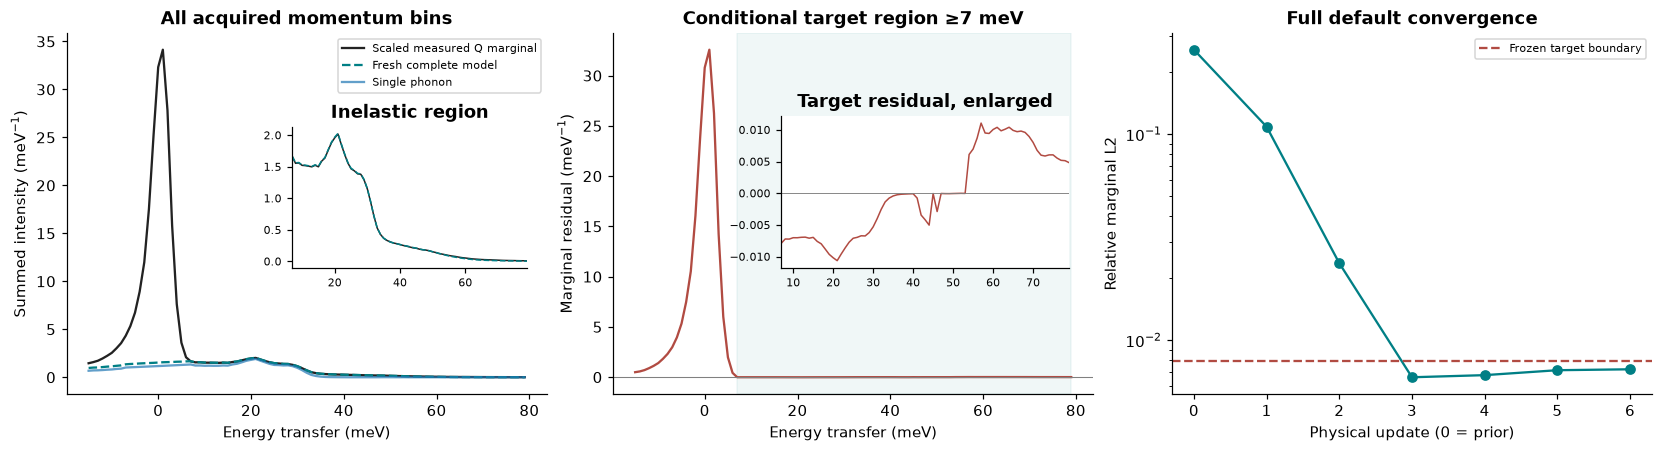

{
  "fresh_metrics": {
    "normalization_abs_error": 0.0,
    "negative_density_max": 0.0,
    "above_support_max": 0.0,
    "low_energy_debye_abs_error": 4.336808689942018e-19,
    "marginal_relative_l2": 0.007229869879588249
  },
  "boundaries": {
    "marginal_relative_l2": {
      "comparison": "<=",
      "boundary": 0.00795285686754709
    },
    "normalization_abs_error": {
      "comparison": "<=",
      "boundary": 5e-06
    },
    "negative_density_max": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "above_support_max": {
      "comparison": "<=",
      "boundary": 1e-09
    },
    "low_energy_debye_abs_error": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  }
}


In [5]:
errors=[judge.score(initial_density(),measured,q)['marginal_relative_l2']]
errors += [judge.score(g,measured,q)['marginal_relative_l2'] for g in fresh['history']]
display(vis.residuals(fresh,q,errors));plt.close()
metrics=judge.score(fresh['reconstruction'],measured,q)
thresholds=judge.configuration(ROOT/'evaluation/metrics.json')
assert all(metrics[k]<=thresholds[k]['boundary'] for k in metrics)
print(json.dumps({'fresh_metrics':metrics,'boundaries':thresholds},indent=2))

A separate mathematical audit distinguishes finite quadrature bias from a normalization claim. The measured-data A1 spectrum has mass below one at1meV. For an independently specified Debye density proportional to $E^2$ through55meV, halving grid spacing approximately halves the defect. Higher-order spectra retain unit discrete mass, and thermal gain/loss spectra satisfy detailed balance. Dotted curves below are the gain spectra multiplied by the Boltzmann factor, not additional reconstruction methods.

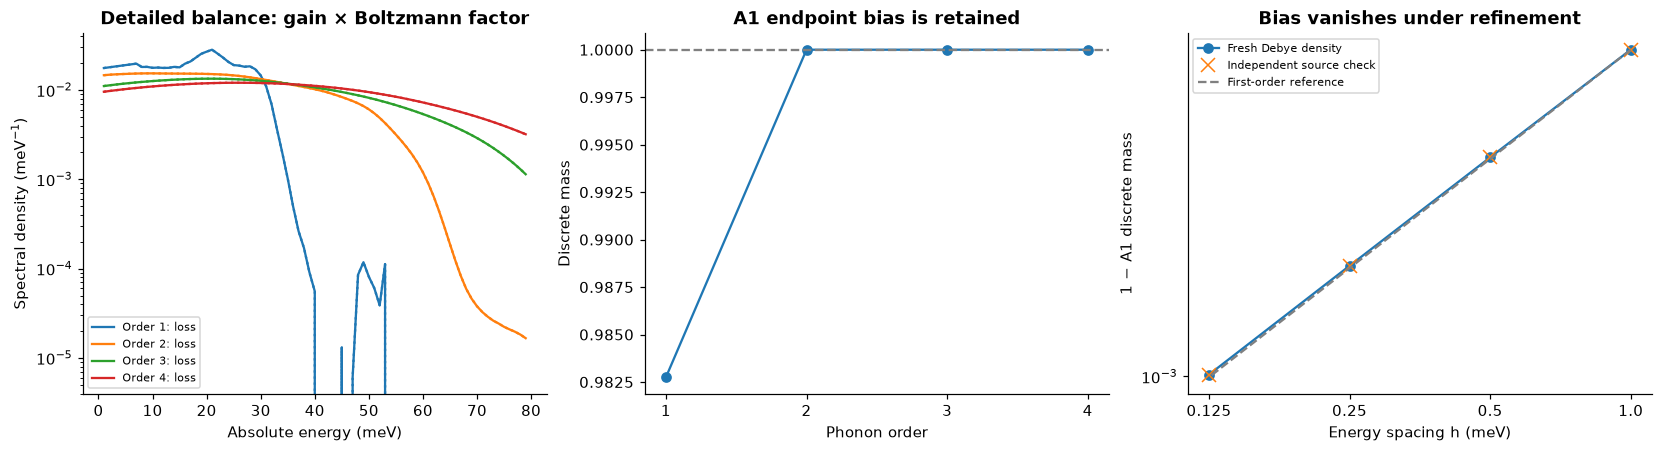

{'A1_mass_default': 0.9827504439260595, 'higher_order_masses': [0.9999999999999998, 1.0, 1.0], 'Debye_grid_masses': [0.99203978197675, 0.9959814972443652, 0.9979811110906723, 0.9989881413719816]}


In [6]:
e,a=spectral_orders(DOS_E,fresh['reconstruction'])
hs=[1.,.5,.25,.125];masses=[]
for h in hs:
    ed=np.arange(round(55/h)+1)*h;gd=ed**2;gd/=gd.sum()*h
    _,ad=spectral_orders(ed,gd,orders=1,step=h)
    masses.append(float(ad[0].sum()*h))
display(vis.balance_bias(e,a,hs,masses,tight_source['a1_mass']));plt.close()
np.testing.assert_allclose(a[:,:79][:,::-1],a[:,80:]*np.exp(-BETA*e[80:]),rtol=1e-9,atol=1e-13)
np.testing.assert_allclose(masses,tight_source['a1_mass'],rtol=1e-10,atol=1e-12)
print({'A1_mass_default':float(a[0].sum()),'higher_order_masses':a[1:].sum(axis=1).tolist(),'Debye_grid_masses':masses})

# 6. Conclusion

The fresh complete default reconstruction reproduces all six original updates and passes the independently defined conditional DOS target. The tighter14-update comparison is also freshly computed and agrees with its separately reproduced source measurement. These are method results rather than true measured DOS.

The integrated residual improves from approximately25.7% for the prior to0.723% for the selected reconstruction. Individual-Q residuals remain substantial under the incoherent approximation, and the finite A1 endpoint bias remains visible. The task therefore supports a clearly stated momentum-marginal inverse conclusion, without claiming detector-noise accuracy or a uniquely identified microscopic density.